# Học dự báo chuỗi thời gian với dữ liệu hành khách hàng không

Notebook này dạy từng bước: xử lý cột ngày tháng, phân rã chuỗi thời gian (xu hướng, mùa vụ), các mô hình dự báo đơn giản, moving average, exponential smoothing (Holt-Winters) và ARIMA/SARIMA.

Dữ liệu: số hành khách đi máy bay quốc tế mỗi tháng (đơn vị: nghìn người) từ tháng 1 năm 1949 đến tháng 12 năm 1960, tổng cộng 144 tháng. Nguồn: Box và Jenkins (1976), bộ flights trong thư viện seaborn.

Điểm khác với các bài trước: dữ liệu có thứ tự thời gian. Không được xáo trộn khi chia train/test, và tập test luôn là phần cuối của chuỗi.

Chuẩn bị:
1. Đặt file data8.csv cùng thư mục với notebook.
2. Cài thư viện nếu chưa có: pip install pandas numpy matplotlib statsmodels scikit-learn

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [1]:
import warnings
warnings.filterwarnings('ignore')  # statsmodels in nhiều cảnh báo về tối ưu, không ảnh hưởng kết quả bài này
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error


def scores(name, actual, forecast):
    actual, forecast = np.asarray(actual), np.asarray(forecast)
    return {'Mô hình': name,
            'MAE': round(mean_absolute_error(actual, forecast), 1),
            'RMSE': round(np.sqrt(mean_squared_error(actual, forecast)), 1),
            'MAPE %': round(np.mean(np.abs((actual - forecast) / actual)) * 100, 2)}

## Bước 1: Đọc dữ liệu

Mục tiêu: đưa file CSV vào DataFrame và kiểm tra kích thước.

Kiến thức: pd.read_csv đọc file thành bảng. Cột month đang là chữ (January, February...).

Kết quả mong đợi: (144, 3). Dòng đầu là 1949, January, 112.

In [2]:
df = pd.read_csv('data8.csv')
print(df.shape)
print(df.head(3))
print(df.dtypes)

(144, 3)
   year     month  passengers
0  1949   January         112
1  1949  February         118
2  1949     March         132
year          int64
month           str
passengers    int64
dtype: object


## Bước 2: Tạo chuỗi thời gian có chỉ số ngày tháng

Mục tiêu: gộp year và month thành một cột ngày, rồi tạo Series y có index là ngày.

Kiến thức: pd.to_datetime chuyển chữ thành kiểu ngày. format="%Y %B" đọc "1949 January". Đặt index là ngày và freq="MS" (month start, đầu mỗi tháng) giúp statsmodels biết khoảng cách giữa hai quan sát là một tháng.

Kết quả mong đợi: y có 144 giá trị, từ 1949-01-01 đến 1960-12-01, freq là MS.

In [3]:
df['date'] = pd.to_datetime(df['year'].astype(str) + ' ' + df['month'], format='%Y %B')
y = df.set_index('date')['passengers'].asfreq('MS')
print(len(y), y.index.min().date(), y.index.max().date(), y.index.freq)

144 1949-01-01 1960-12-01 <MonthBegin>


## Bước 3: Vẽ chuỗi thời gian

Mục tiêu: nhận ra xu hướng và mùa vụ bằng mắt.

Kiến thức: xu hướng (trend) là hướng đi dài hạn. Mùa vụ (seasonality) là mẫu lặp lại theo chu kỳ cố định, ở đây là 12 tháng. Nếu biên độ mùa vụ lớn dần theo thời gian, ta gọi là mùa vụ nhân (multiplicative).

Kết quả mong đợi: chuỗi tăng đều từ khoảng 100 lên khoảng 600. Mỗi năm có đỉnh vào mùa hè. Biên độ dao động năm 1960 lớn hơn nhiều so với năm 1949.

Câu hỏi: mùa vụ ở đây là cộng (additive) hay nhân (multiplicative)? Vì sao?

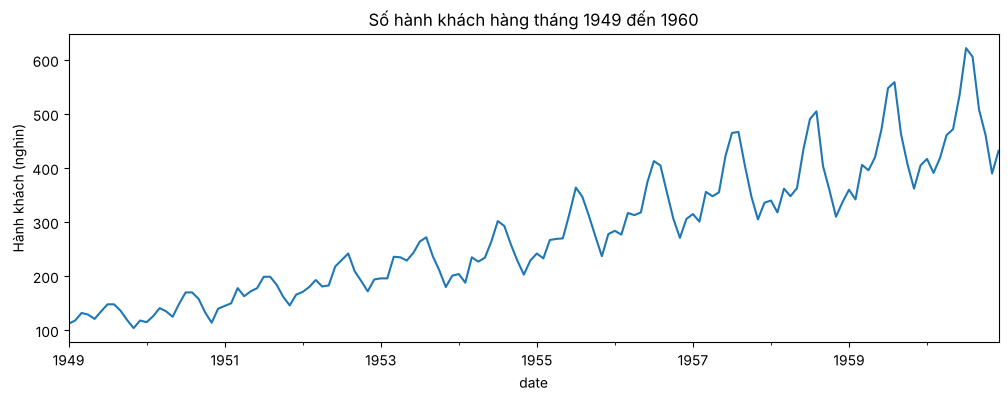

In [4]:
y.plot(figsize=(12, 4))
plt.ylabel('Hành khách (nghìn)')
plt.title('Số hành khách hàng tháng 1949 đến 1960')
plt.show()

## Bước 4: Mẫu theo tháng

Mục tiêu: xem tháng nào đông khách nhất.

Kiến thức: pivot_table với index là year, columns là tháng cho bảng 12 x 12. Chia mỗi dòng cho trung bình của năm đó cho ra chỉ số mùa vụ: 1,2 nghĩa là tháng đó cao hơn trung bình năm 20%.

Kết quả mong đợi: tháng 7 và tháng 8 cao nhất, khoảng 1,24 (cao hơn trung bình năm khoảng 24%). Tháng 11 thấp nhất, khoảng 0,83. Trên hình, đường của các năm sau nằm cao hơn và dao động mạnh hơn.

date
1     0.861
2     0.852
3     0.980
4     0.959
5     0.966
6     1.103
7     1.236
8     1.237
9     1.081
10    0.951
11    0.832
12    0.942
dtype: float64


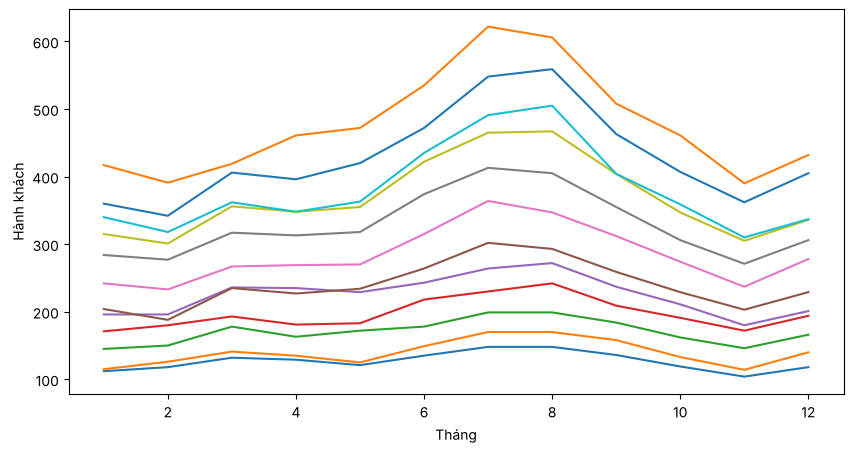

In [5]:
tbl = y.groupby([y.index.year, y.index.month]).sum().unstack()
seasonal_index = tbl.div(tbl.mean(axis=1), axis=0)
print(seasonal_index.mean().round(3))
tbl.T.plot(figsize=(10, 5), legend=False)
plt.xlabel('Tháng')
plt.ylabel('Hành khách')
plt.show()

## Bước 5: Phân rã chuỗi thời gian

Mục tiêu: tách chuỗi thành xu hướng, mùa vụ và phần dư.

Kiến thức: seasonal_decompose với model="multiplicative" giả định y = trend x seasonal x residual. Trend được ước lượng bằng moving average 12 tháng (nên 6 tháng đầu và 6 tháng cuối bị trống).

Kết quả mong đợi: 4 hình: chuỗi gốc, trend tăng gần như tuyến tính, seasonal lặp lại mỗi năm và residual quanh 1. Hệ số mùa vụ tháng 7 khoảng 1,227, tháng 11 khoảng 0,801.

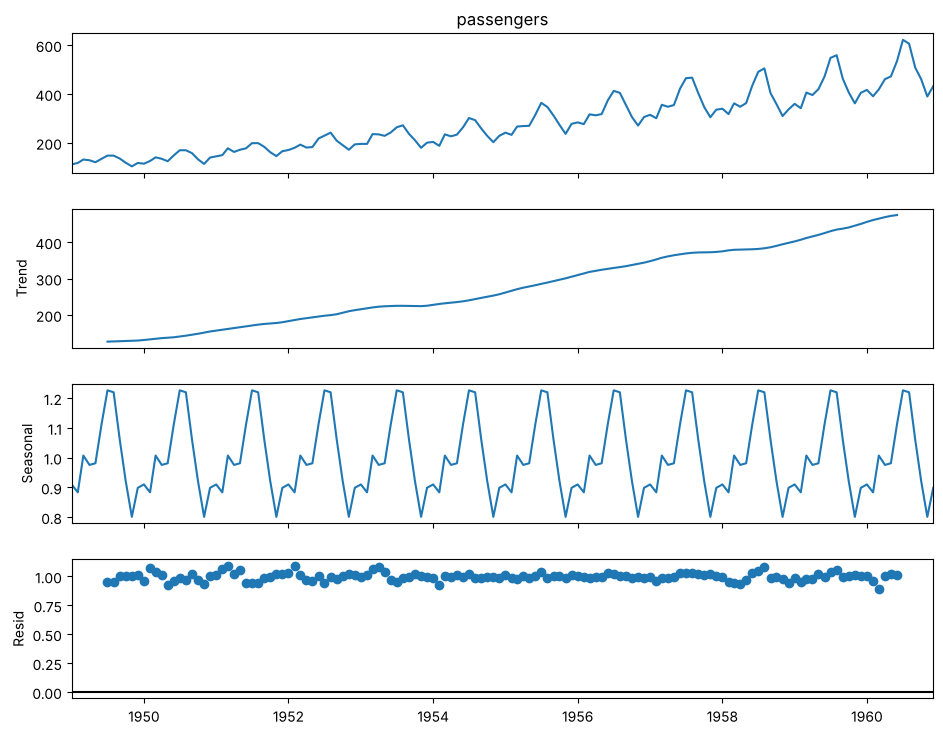

date
1949-01-01    0.910
1949-02-01    0.884
1949-03-01    1.007
1949-04-01    0.976
1949-05-01    0.981
1949-06-01    1.113
1949-07-01    1.227
1949-08-01    1.220
1949-09-01    1.060
1949-10-01    0.922
1949-11-01    0.801
1949-12-01    0.899
Freq: MS, Name: seasonal, dtype: float64


In [6]:
dec = seasonal_decompose(y, model='multiplicative', period=12)
fig = dec.plot()
fig.set_size_inches(10, 8)
plt.show()
print(dec.seasonal[:12].round(3))

## Bước 6: Biến đổi log

Mục tiêu: biến mùa vụ nhân thành mùa vụ cộng.

Kiến thức: log(a x b) = log(a) + log(b). Sau khi lấy log, biên độ dao động gần như không đổi theo thời gian. Nhiều mô hình (như ARIMA) làm việc tốt hơn với chuỗi có phương sai ổn định.

Kết quả mong đợi: trên chuỗi gốc, độ lệch chuẩn trong năm tăng từ 13,7 (1949) lên 77,7 (1960), tăng hơn 5 lần. Sau khi lấy log, con số này chỉ từ 0,108 lên 0,157.

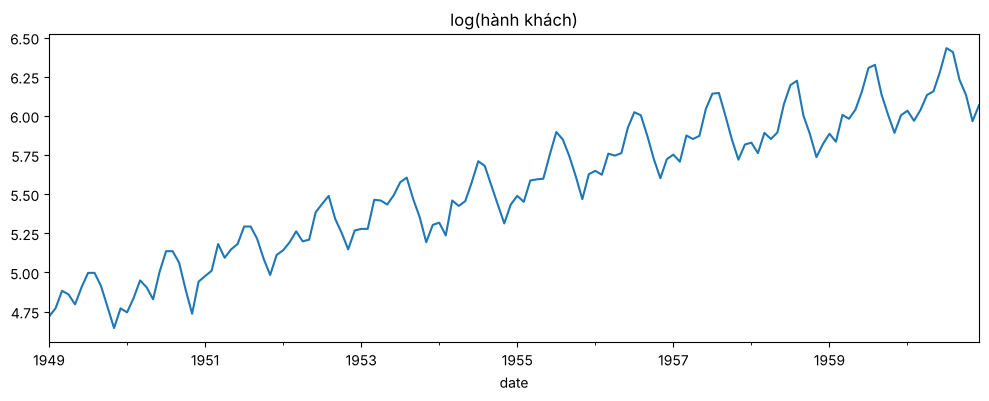

1949 | std của y: 13.7 | std của log y: 0.108
1960 | std của y: 77.7 | std của log y: 0.157


In [7]:
y_log = np.log(y)
y_log.plot(figsize=(12, 4), title='log(hành khách)')
plt.show()
for yr in ['1949', '1960']:
    print(yr, '| std của y:', round(y[yr].std(), 1), '| std của log y:', round(y_log[yr].std(), 3))

## Bước 7: Chia train và test theo thời gian

Mục tiêu: dùng 10 năm đầu để học và 2 năm cuối để kiểm tra.

Kiến thức: train_test_split xáo trộn dữ liệu, nên không dùng cho chuỗi thời gian. Cắt bằng index ngày: mọi thứ trước 1959 là train, từ 1959 trở đi là test. Như vậy mô hình chỉ dùng quá khứ để dự báo tương lai.

Kết quả mong đợi: train có 120 tháng (1949-01 đến 1958-12), test có 24 tháng (1959-01 đến 1960-12).

In [8]:
train = y[:'1958']
test = y['1959':]
print('train:', len(train), train.index[0].date(), train.index[-1].date())
print('test :', len(test), test.index[0].date(), test.index[-1].date())

train: 120 1949-01-01 1958-12-01
test : 24 1959-01-01 1960-12-01


## Bước 8: Các mô hình dự báo ngây thơ

Mục tiêu: có baseline mà mọi mô hình phải vượt qua.

Kiến thức: naive: mọi tháng tương lai bằng tháng cuối cùng của train. Seasonal naive: mỗi tháng tương lai bằng cùng tháng của năm cuối cùng trong train. Hàm scores ở bước 0 tính MAE, RMSE và MAPE (sai số phần trăm tuyệt đối trung bình). Với 24 tháng test, seasonal naive lặp lại năm 1958 hai lần.

Kết quả mong đợi: Naive: MAPE khoảng 23,58%. Seasonal naive: MAE khoảng 71,2, RMSE khoảng 77,0, MAPE khoảng 15,52%.

Câu hỏi: seasonal naive giữ được mùa vụ nhưng vẫn sai nhiều. Nó thiếu thành phần nào?

In [9]:
naive = np.repeat(train.iloc[-1], len(test))
snaive = np.tile(train[-12:].values, 2)
results = [scores('Naive', test, naive), scores('Seasonal naive', test, snaive)]
print(pd.DataFrame(results))

          Mô hình    MAE   RMSE  MAPE %
0           Naive  115.2  137.3   23.58
1  Seasonal naive   71.2   77.0   15.52


## Bước 9: Moving average

Mục tiêu: làm mượt chuỗi bằng trung bình trượt và dùng nó để dự báo.

Kiến thức: rolling(12).mean() tính trung bình của 12 tháng gần nhất tại mỗi thời điểm. Cửa sổ 12 tháng xóa mùa vụ và để lại xu hướng. Dự báo bằng moving average: lấy trung bình 12 tháng cuối của train cho mọi tháng tương lai. Cách này cho đường thẳng, không có mùa vụ và không có xu hướng.

Kết quả mong đợi: đường MA 12 tháng mượt và tăng đều, không còn dao động mùa vụ. Dự báo moving average có MAPE khoảng 15,47%, gần bằng seasonal naive nhưng RMSE lớn hơn (khoảng 103,2).

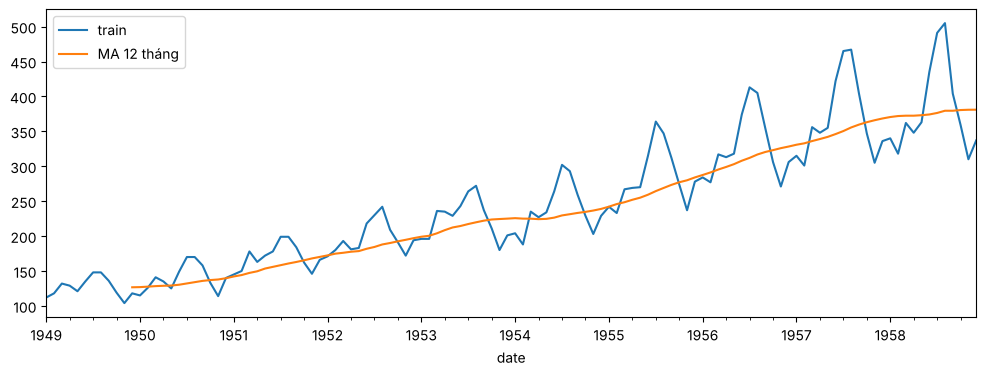

             Mô hình    MAE   RMSE  MAPE %
0              Naive  115.2  137.3   23.58
1     Seasonal naive   71.2   77.0   15.52
2  Moving average 12   77.8  103.2   15.47

In [10]:
ax = train.plot(figsize=(12, 4), label='train')
train.rolling(12).mean().plot(ax=ax, label='MA 12 tháng')
plt.legend()
plt.show()
ma_forecast = np.repeat(train[-12:].mean(), len(test))
results.append(scores('Moving average 12', test, ma_forecast))
print(pd.DataFrame(results))

## Bước 10: Simple exponential smoothing

Mục tiêu: dự báo bằng trung bình có trọng số giảm dần về quá khứ.

Kiến thức: SES đặt trọng số alpha cho quan sát mới nhất, alpha(1 - alpha) cho quan sát trước đó, và cứ thế giảm dần. alpha gần 1 thì mô hình gần như chỉ nhìn tháng cuối. SES không có xu hướng và mùa vụ, nên dự báo vẫn là một đường thẳng.

Kết quả mong đợi: alpha bằng 1,0, tức là SES chỉ nhìn tháng cuối cùng. Kết quả gần như trùng với naive (MAPE khoảng 23,58%).

In [11]:
ses = SimpleExpSmoothing(train, initialization_method='estimated').fit()
print('alpha =', round(ses.params['smoothing_level'], 3))
ses_fc = ses.forecast(len(test))
results.append(scores('SES', test, ses_fc))
print(pd.DataFrame(results))

alpha = 1.0
             Mô hình    MAE   RMSE  MAPE %
0              Naive  115.2  137.3   23.58
1     Seasonal naive   71.2   77.0   15.52
2  Moving average 12   77.8  103.2   15.47
3                SES  115.3  137.3   23.58


## Bước 11: Holt-Winters

Mục tiêu: thêm xu hướng và mùa vụ vào exponential smoothing.

Kiến thức: ExponentialSmoothing của statsmodels có 3 thành phần: level (mức), trend (xu hướng) và seasonal (mùa vụ). trend="add" cho xu hướng tăng đều. seasonal="mul" cho mùa vụ nhân, hợp với chuỗi ở bước 3. seasonal_periods=12.

Kết quả mong đợi: MAE khoảng 29,0, RMSE khoảng 32,5, MAPE khoảng 6,39%. Đường dự báo bám sát cả xu hướng và các đỉnh mùa hè của tập test.

             Mô hình    MAE   RMSE  MAPE %
0              Naive  115.2  137.3   23.58
1     Seasonal naive   71.2   77.0   15.52
2  Moving average 12   77.8  103.2   15.47
3                SES  115.3  137.3   23.58
4       Holt-Winters   29.0   32.5    6.39


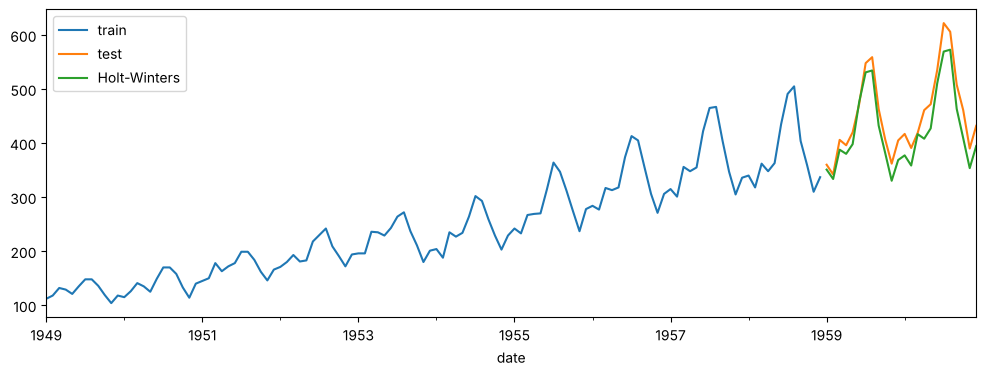

In [12]:
hw = ExponentialSmoothing(train, trend='add', seasonal='mul', seasonal_periods=12, initialization_method='estimated').fit()
hw_fc = hw.forecast(len(test))
results.append(scores('Holt-Winters', test, hw_fc))
print(pd.DataFrame(results))

ax = train.plot(figsize=(12, 4), label='train')
test.plot(ax=ax, label='test')
hw_fc.plot(ax=ax, label='Holt-Winters')
plt.legend()
plt.show()

## Bước 12: Kiểm tra tính dừng

Mục tiêu: biết chuỗi cần lấy sai phân bao nhiêu lần trước khi dùng ARIMA.

Kiến thức: ARIMA cần chuỗi dừng (stationary): trung bình và phương sai không đổi theo thời gian. Kiểm định ADF có giả thuyết H0 là chuỗi không dừng. p-value dưới 0,05 thì bác bỏ H0, tức là chuỗi dừng. Sai phân bậc 1 (diff(1)) xóa xu hướng. Sai phân mùa vụ (diff(12)) xóa mùa vụ.

Kết quả mong đợi: log y có p-value khoảng 0,42 (không dừng). Sau diff(1) khoảng 0,071 (vẫn chưa dừng ở mức 0,05). Sau diff(1) và diff(12) khoảng 0,0002 (dừng).

Câu hỏi: vì sao chuỗi sau diff(1) vẫn chưa dừng? Gợi ý: nhìn lại bước 4.

log y              p-value = 0.4224
diff 1             p-value = 0.0711
diff 1 + diff 12   p-value = 0.0002


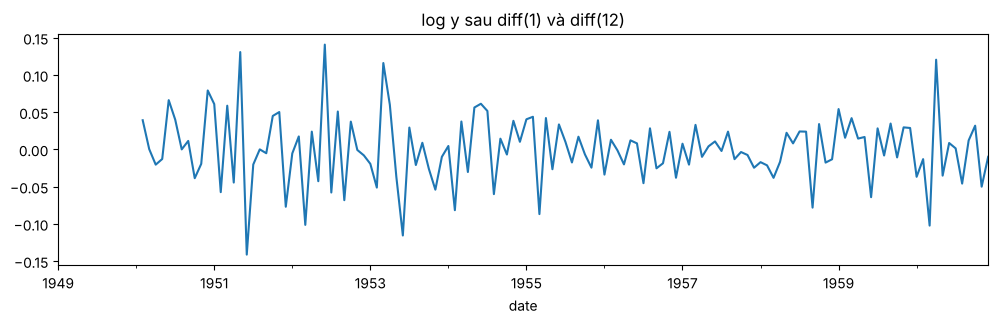

In [13]:
def adf_p(s):
    return adfuller(s.dropna())[1]

for name, s in [('log y', y_log), ('diff 1', y_log.diff(1)), ('diff 1 + diff 12', y_log.diff(1).diff(12))]:
    print(f'{name:18s} p-value = {adf_p(s):.4f}')
y_log.diff(1).diff(12).plot(figsize=(12, 3), title='log y sau diff(1) và diff(12)')
plt.show()

## Bước 13: ACF và PACF

Mục tiêu: đọc biểu đồ tự tương quan để gợi ý bậc của ARIMA.

Kiến thức: ACF (autocorrelation function) đo tương quan giữa chuỗi và chính nó trễ k tháng. PACF đo tương quan đó sau khi đã loại ảnh hưởng của các độ trễ ngắn hơn. Cột vượt ra ngoài vùng tô màu là có ý nghĩa thống kê. Quy tắc thô: ACF tắt sau độ trễ q thì gợi ý MA(q), PACF tắt sau độ trễ p thì gợi ý AR(p).

Kết quả mong đợi: trên chuỗi đã sai phân, ACF có cột lớn ở độ trễ 1 và độ trễ 12. Điều này gợi ý thành phần MA(1) và MA(1) mùa vụ.

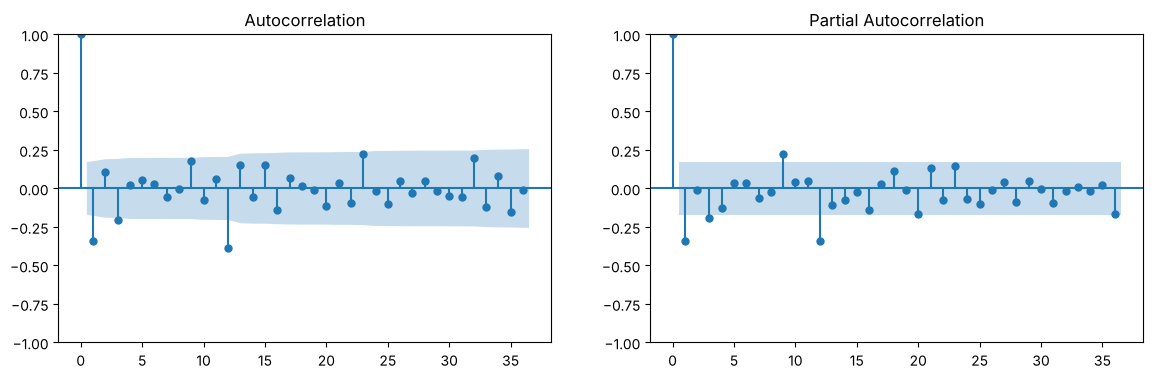

In [14]:
d = y_log.diff(1).diff(12).dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(d, lags=36, ax=axes[0])
plot_pacf(d, lags=36, ax=axes[1])
plt.show()

## Bước 14: SARIMA (airline model)

Mục tiêu: huấn luyện mô hình ARIMA có mùa vụ trên log của chuỗi.

Kiến thức: SARIMA(p, d, q)(P, D, Q, s): p, d, q cho phần thường, P, D, Q cho phần mùa vụ với chu kỳ s. Mô hình (0, 1, 1)(0, 1, 1, 12) được Box và Jenkins dùng cho chính bộ dữ liệu này nên gọi là airline model. Vì mô hình học trên log, dự báo cần đổi lại bằng np.exp.

Kết quả mong đợi: ma.L1 khoảng -0,343 và ma.S.L12 khoảng -0,541, cả hai có p-value dưới 0,001. SARIMA có MAPE khoảng 8,51%, tốt hơn các baseline nhưng kém Holt-Winters (6,39%) trên tập test này.

In [15]:
sar = SARIMAX(np.log(train), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sar.summary().tables[1])
fc = sar.get_forecast(len(test))
sar_fc = np.exp(fc.predicted_mean)
results.append(scores('SARIMA', test, sar_fc))
print(pd.DataFrame(results))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3425      0.087     -3.923      0.000      -0.514      -0.171
ma.S.L12      -0.5407      0.105     -5.157      0.000      -0.746      -0.335
sigma2         0.0014      0.000      7.865      0.000       0.001       0.002
             Mô hình    MAE   RMSE  MAPE %
0              Naive  115.2  137.3   23.58
1     Seasonal naive   71.2   77.0   15.52
2  Moving average 12   77.8  103.2   15.47
3                SES  115.3  137.3   23.58
4       Holt-Winters   29.0   32.5    6.39
5             SARIMA   39.4   43.2    8.51


## Bước 15: Khoảng tin cậy của dự báo

Mục tiêu: vẽ dự báo kèm khoảng tin cậy 95%.

Kiến thức: conf_int() trả về cận dưới và cận trên trong thang log. Đổi lại bằng np.exp. Khoảng tin cậy rộng dần theo thời gian vì càng xa càng khó đoán.

Kết quả mong đợi: khoảng tin cậy rộng dần về cuối năm 1960. Cả 24 trên 24 tháng test nằm trong khoảng 95%.

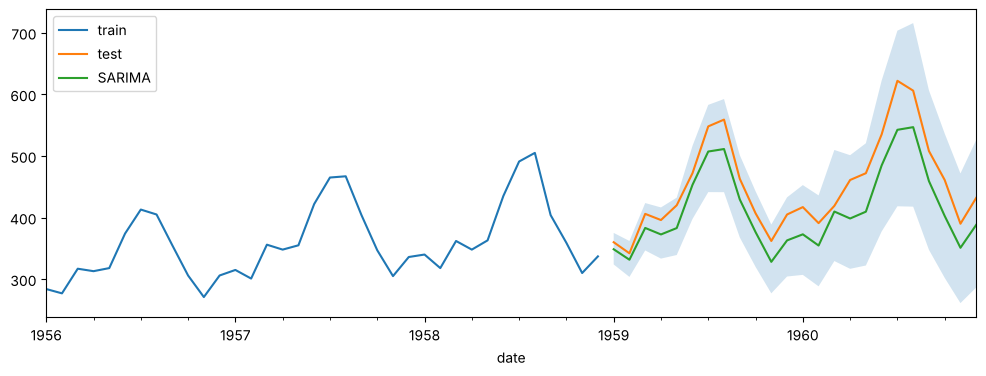

Số tháng test nằm trong khoảng 95%: 24 / 24


In [16]:
ci = np.exp(fc.conf_int())
ax = train[-36:].plot(figsize=(12, 4), label='train')
test.plot(ax=ax, label='test')
sar_fc.plot(ax=ax, label='SARIMA')
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2)
plt.legend()
plt.show()
inside = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).sum()
print('Số tháng test nằm trong khoảng 95%:', inside, '/', len(test))

## Bước 16: Kiểm tra phần dư

Mục tiêu: xem mô hình đã lấy hết thông tin trong chuỗi chưa.

Kiến thức: nếu mô hình tốt, phần dư giống nhiễu trắng: không còn tự tương quan. Kiểm định Ljung-Box có H0 là không có tự tương quan. p-value lớn hơn 0,05 là tốt. plot_diagnostics vẽ 4 hình kiểm tra phần dư.

Kết quả mong đợi: p-value Ljung-Box ở độ trễ 12 khoảng 0,91, ở độ trễ 24 khoảng 0,80. Cả hai đều lớn hơn 0,05, nên phần dư không còn tự tương quan.

      lb_stat  lb_pvalue
12   6.071813   0.912419
24  17.984942   0.803738


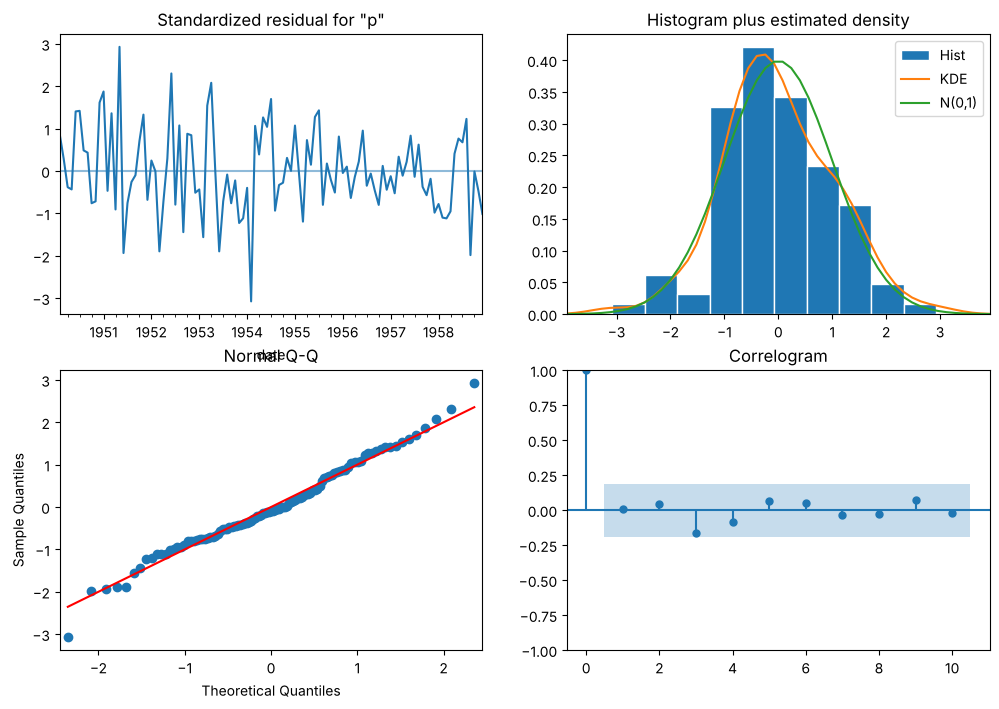

In [17]:
print(acorr_ljungbox(sar.resid[13:], lags=[12, 24]))
sar.plot_diagnostics(figsize=(12, 8))
plt.show()

## Bước 17: Bảng so sánh và dự báo năm 1961

Mục tiêu: chọn mô hình tốt nhất, huấn luyện lại trên toàn bộ dữ liệu và dự báo 12 tháng tiếp theo.

Kiến thức: sau khi chọn được mô hình bằng tập test, ta huấn luyện lại trên toàn bộ 144 tháng để dùng hết thông tin mới nhất.

Kết quả mong đợi: Holt-Winters đứng đầu (MAPE khoảng 6,39%), SARIMA thứ hai (khoảng 8,51%). Dự báo năm 1961 có đỉnh khoảng 670 nghìn hành khách vào tháng 7 và thấp nhất khoảng 426 nghìn vào tháng 2.

Câu hỏi: MAPE của mô hình tốt nhất là bao nhiêu? Một hãng hàng không có thể dùng sai số đó để lên kế hoạch số chuyến bay không?

             Mô hình    MAE   RMSE  MAPE %
4       Holt-Winters   29.0   32.5    6.39
5             SARIMA   39.4   43.2    8.51
2  Moving average 12   77.8  103.2   15.47
1     Seasonal naive   71.2   77.0   15.52
3                SES  115.3  137.3   23.58
0              Naive  115.2  137.3   23.58
1961-01-01    450.0
1961-02-01    426.0
1961-03-01    479.0
1961-04-01    492.0
1961-05-01    509.0
1961-06-01    583.0
1961-07-01    670.0
1961-08-01    667.0
1961-09-01    558.0
1961-10-01    497.0
1961-11-01    430.0
1961-12-01    477.0
Freq: MS, Name: predicted_mean, dtype: float64


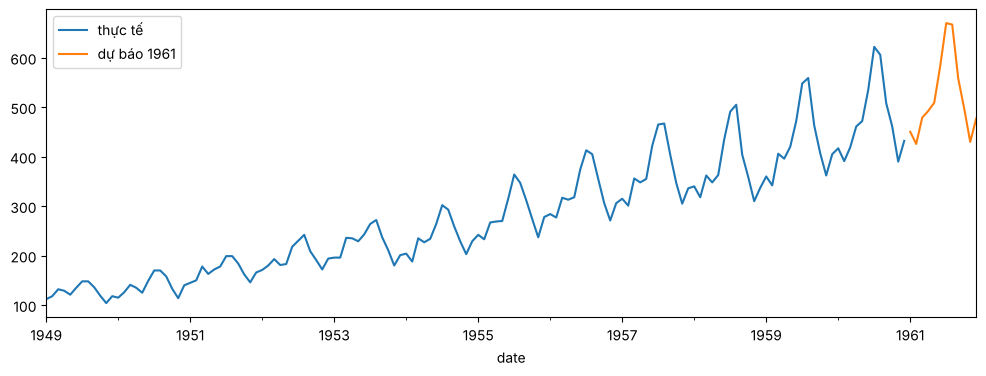

In [18]:
print(pd.DataFrame(results).sort_values('MAPE %').to_string())
final = SARIMAX(np.log(y), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
fc_1961 = np.exp(final.get_forecast(12).predicted_mean)
print(fc_1961.round(0))
ax = y.plot(figsize=(12, 4), label='thực tế')
fc_1961.plot(ax=ax, label='dự báo 1961')
plt.legend()
plt.show()

## Bước 18: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Chạy Holt-Winters với seasonal='add' thay vì 'mul'. MAPE thay đổi thế nào? Kết quả có khớp với nhận xét ở bước 3 không?
2. Thử SARIMA với order (1, 1, 1) hoặc (2, 1, 0) và so sánh chỉ số AIC trong summary. AIC nhỏ hơn là tốt hơn.
3. Chạy SARIMA trên y gốc (không lấy log). Dự báo có tệ hơn không?
4. Viết ba câu tiếng Anh mô tả chuỗi và kết quả dự báo. Ví dụ: "Monthly passenger numbers rose from 112 thousand in January 1949 to 432 thousand in December 1960, with a peak every July and August."
